# 04 Diagramme und Empfehlungen
In diesem Notebook entstehen die Diagramme für die README (gespeichert in `docs/figures`) sowie die Handlungsempfehlungen für das Management. Die Berechnungen stammen aus Notebook 03.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("sqlite:///../data/processed/maven_toys.db")
connection = engine.connect()

sales_full = pd.read_sql("SELECT * FROM sales_full", connection, parse_dates=["Date"])
inventory_full = pd.read_sql("SELECT * FROM inventory_full", connection)

Path("../docs/figures").mkdir(parents=True, exist_ok=True)
print(sales_full.shape, inventory_full.shape)

(829262, 15) (1593, 11)


## Grundlage: ABC-Analyse
Die Diagramme in diesem Notebook beruhen auf der ABC-Analyse aus Notebook 03. Dafür wird der Gewinn je Produkt berechnet und die Produkte werden nach ihrem Beitrag zum Gesamtgewinn in die Klassen A, B und C eingeteilt.

In [ ]:
product_profit = (
    sales_full.groupby("Product_Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

product_profit["Share_Pct"] = product_profit["Profit"] / product_profit["Profit"].sum() * 100
product_profit["Cumulative_Pct"] = product_profit["Share_Pct"].cumsum()
product_profit["ABC_Class"] = pd.cut(
    product_profit["Cumulative_Pct"] - product_profit["Share_Pct"],
    bins=[-1, 80, 95, 101],
    labels=["A", "B", "C"],
)

product_profit.round(1)

,Product_Name,Profit,Share_Pct,Cumulative_Pct,ABC_Class
0,Colorbuds,834944.0,20.8,20.8,A
1,Action Figure,347748.0,8.7,29.5,A
2,Lego Bricks,298685.0,7.4,36.9,A
3,Deck Of Cards,252102.0,6.3,43.2,A
4,Glass Marbles,187590.0,4.7,47.9,A
5,Barrel O' Slime,183326.0,4.6,52.4,A
6,Kids Makeup Kit,146598.0,3.7,56.1,A
7,Nerf Gun,132715.0,3.3,59.4,A
8,Dart Gun,126352.0,3.1,62.5,A
9,Etch A Sketch,121680.0,3.0,65.6,A


In [ ]:
product_profit.groupby("ABC_Class", observed=True).agg(
    Products=("Product_Name", "count"),
    Profit=("Profit", "sum"),
)

,Products,Profit
ABC_Class,,
A,16,3297939.0
B,9,531014.0
C,10,185076.0


### Diagramm: Pareto-Analyse
Die Balken zeigen den Gewinnanteil je Produkt, die Linie den kumulierten Anteil. Die Farben markieren die ABC-Klassen.

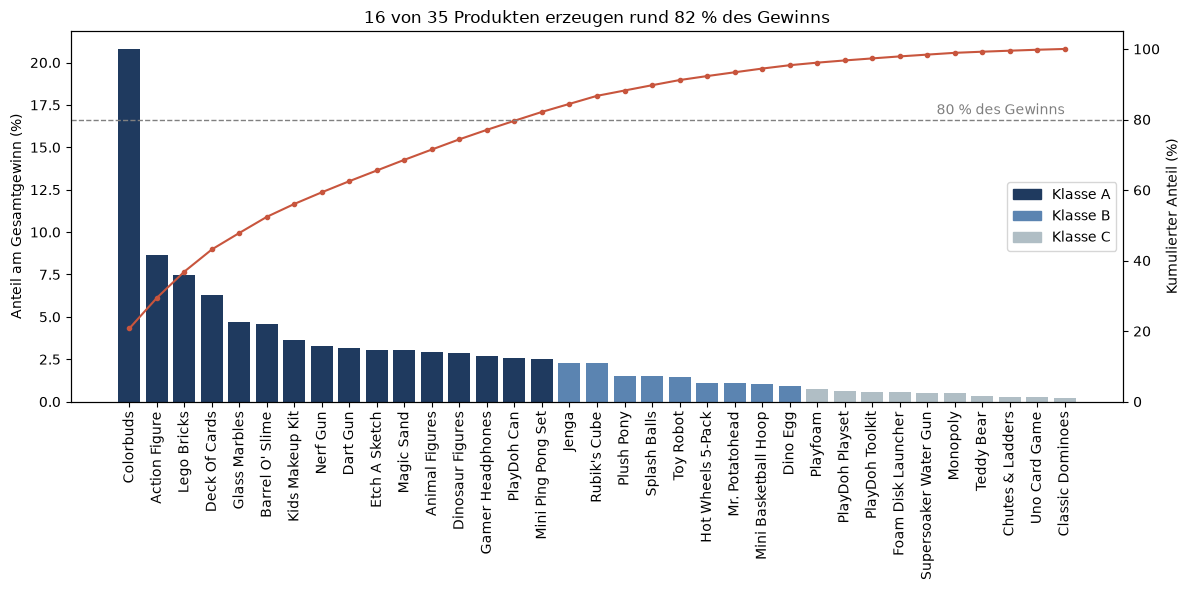

In [ ]:
from pathlib import Path

from matplotlib.patches import Patch

Path("../docs/figures").mkdir(parents=True, exist_ok=True)

class_colors = {"A": "#1F3A5F", "B": "#5B84B1", "C": "#B0BEC5"}
bar_colors = product_profit["ABC_Class"].astype(str).map(class_colors).tolist()

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.bar(product_profit["Product_Name"], product_profit["Share_Pct"], color=bar_colors)
ax1.set_ylabel("Anteil am Gesamtgewinn (%)")
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()
ax2.plot(product_profit["Product_Name"], product_profit["Cumulative_Pct"],
         color="#C8553D", marker="o", markersize=3)
ax2.axhline(80, color="grey", linestyle="--", linewidth=1)
ax2.text(len(product_profit) - 1, 81.5, "80 % des Gewinns", ha="right", color="grey")
ax2.set_ylabel("Kumulierter Anteil (%)")
ax2.set_ylim(0, 105)

ax1.legend(handles=[Patch(color=c, label=f"Klasse {k}") for k, c in class_colors.items()], loc="center right")
ax1.set_title("16 von 35 Produkten erzeugen rund 82 % des Gewinns")
plt.tight_layout()
plt.savefig("../docs/figures/pareto_abc.png", dpi=150)
plt.show()

## Diagramm: Gewinn je Monat und Abhängigkeit von Colorbuds
Die Balken zeigen den Gewinn je Monat, die Linie den Anteil von Colorbuds daran.

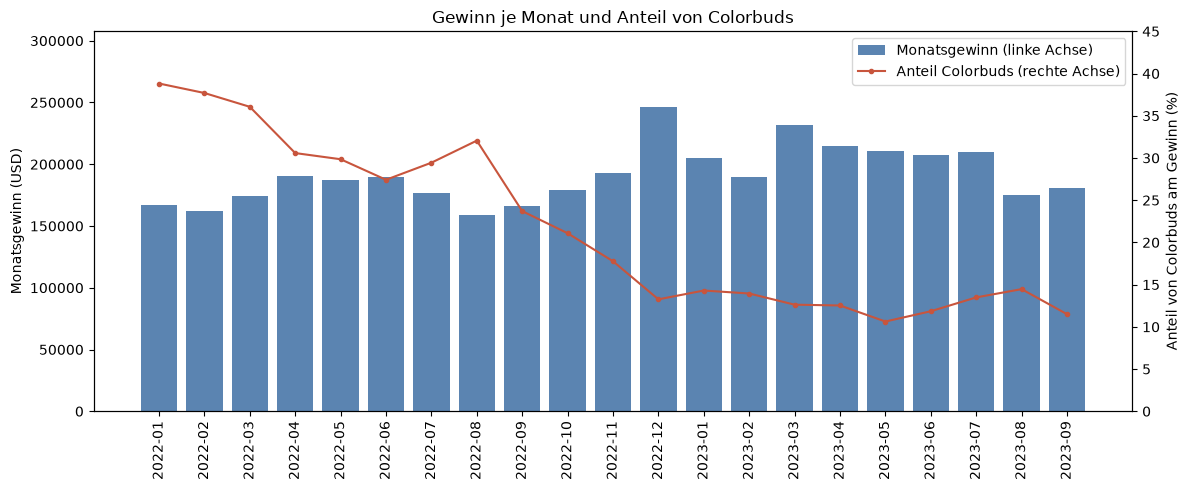

In [4]:
query_stability = """
SELECT
    strftime('%Y-%m', Date) AS Month,
    SUM(Profit) AS Profit,
    SUM(CASE WHEN Product_Name = 'Colorbuds' THEN Profit ELSE 0 END) AS Colorbuds_Profit
FROM sales_full
GROUP BY Month
"""
monthly = pd.read_sql(query_stability, connection)
monthly["Colorbuds_Share"] = monthly["Colorbuds_Profit"] / monthly["Profit"] * 100

fig, ax1 = plt.subplots(figsize=(12, 5))
bars = ax1.bar(monthly["Month"], monthly["Profit"], color="#5B84B1", label="Monatsgewinn (linke Achse)")
ax1.set_ylabel("Monatsgewinn (USD)")
ax1.set_ylim(0, monthly["Profit"].max() * 1.25)
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()
line, = ax2.plot(monthly["Month"], monthly["Colorbuds_Share"], color="#C8553D",
                 marker="o", markersize=3, label="Anteil Colorbuds (rechte Achse)")
ax2.set_ylabel("Anteil von Colorbuds am Gewinn (%)")
ax2.set_ylim(0, 45)

ax1.legend(handles=[bars, line], loc="upper right")
ax1.set_title("Gewinn je Monat und Anteil von Colorbuds")
plt.tight_layout()
plt.savefig("../docs/figures/stabilitaet_colorbuds.png", dpi=150)
plt.show()

## Handlungsempfehlungen

1. **Rückgang von Colorbuds untersuchen.**
   Colorbuds ist das gewinnstärkste Produkt (20,8 % des Gesamtgewinns), verliert aber seit Januar 2022 kontinuierlich und ist der größte Einzelfaktor beim Gewinnrückgang des Bestandssortiments. Preise und Kosten sind im Datensatz konstant, und die Gamer Headphones erklären den Rückgang nicht. Die Ursache ist aus diesen Daten nicht erkennbar und sollte mit zusätzlichen Informationen geklärt werden (zum Beispiel Wettbewerb, Produktlebenszyklus, Verfügbarkeit).

2. **Neueinführungen gezielt fördern, das Bestandssortiment prüfen.**
   Das Wachstum 2023 kommt vollständig von elf neuen Produkten (+352.376 USD Gewinn), während die 24 Bestandsprodukte zusammen 100.171 USD verlieren. Mehrere Neueinführungen (Etch A Sketch, Magic Sand, Gamer Headphones) gehören bereits zur A-Klasse. Eine Pipeline neuer Produkte ist damit ein wichtiger Wachstumshebel, und schwache Bestandsprodukte sollten regelmäßig bewertet werden.

3. **Marge neben dem Umsatz steuern.**
   Der Umsatz steigt von Januar bis September um 31 %, der Gewinn nur um 16 %, und die Marge sinkt von 29,5 % auf 26,2 %. Der Rückgang zeigt sich in allen Filialtypen und kommt aus dem Produktmix, nicht aus Preisänderungen. Bei Sortiments- und Aktionsentscheidungen sollte deshalb die Marge als Kennzahl neben dem Umsatz berücksichtigt werden.

4. **Fehlbestände bei Schnelldrehern vermeiden.**
   Die Reichweite liegt bei vielen Produkten bei nur 0,2 bis 0,4 Monaten (Dino Egg, Hot Wheels 5-Pack, Etch A Sketch, Playfoam). Aktuell haben 77 von 1.593 Produkt-Filial-Kombinationen (4,8 %) keinen Bestand, am häufigsten Playfoam (13 Filialen) und Hot Wheels 5-Pack (12). Für diese Produkte sollten Mindestbestände festgelegt werden. Bei Teddy Bear und Plush Pony fehlt der Bestand in einzelnen Filialen trotz hoher Gesamtreichweite, hier sollte die Verteilung zwischen den Filialen geprüft werden.

5. **Überbestand gezielt abbauen.**
   Bei einer Zielreichweite von einem Monat liegen 25.383 USD (8,5 % des Lagerwerts) über dem Bedarf, davon rund 60 % bei Dinosaur Figures, PlayDoh Playset und Supersoaker Water Gun. Das Potenzial ist klein, der Abbau bei diesen drei Produkten aber einfach. Saisonale Produkte sollten dabei nach Jahreszeit beurteilt werden.

6. **Standortfokus prüfen.**
   Filialen im Standorttyp Downtown erzeugen rund 57 % des Gewinns. Pro Filiale ist Airport am stärksten, es gibt aber nur drei Filialen. Downtown sollte als Rückgrat des Geschäfts gesichert werden, und das Potenzial weiterer Airport-Standorte kann geprüft werden.

**Hinweis zur Belastbarkeit:** Die Empfehlungen beruhen auf 21 Monaten fiktiver Verkaufsdaten ohne Kunden-, Rabatt- und Preisverlaufsdaten. Die Lagerdaten sind eine Momentaufnahme. Die Empfehlungen sind daher Hypothesen für die weitere Prüfung und keine fertigen Entscheidungen.